In [82]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pandas_datareader import data as pdr

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
pd.options.display.float_format = "{:,.6f}".format

# Macroeconomic Factor Data Plan

## 1. 研究目标

在完成strategic benchmark的构建后，项目的下一阶段是构建一组具有明确经济含义的macroeconomic factors。

这些宏观因子将用于解释并预测不同资产类别下一期的excess returns，随后进一步形成tactical overweight或underweight positions。

本研究选择五类核心宏观因子：

1. Growth；
2. Inflation；
3. Interest Rates；
4. Credit Conditions；
5. Risk Sentiment。

宏观因子向量可以表示为：

$$
\mathbf{F}_t
=
\begin{bmatrix}
Growth_t \\
Inflation_t \\
Rates_t \\
Credit_t \\
Sentiment_t
\end{bmatrix}.
$$

这些因子将在月末构建，并用于预测各项资产在下一个月的excess return。

---

## 2. Macro Data Dictionary

本研究使用Federal Reserve Economic Data（FRED）作为主要宏观数据来源。

第一版模型中，每类宏观因子选择一个具有代表性的变量，以保持模型的经济可解释性，并降低overfitting和multicollinearity风险。

| Macro Factor | FRED Series | Raw Variable | Transformation | Information Lag |
|---|---|---|---|---|
| Growth | `INDPRO` | Industrial Production Index | 12-month year-over-year growth rate | 1 month |
| Inflation | `CPIAUCSL` | Consumer Price Index for All Urban Consumers | 12-month year-over-year inflation rate | 1 month |
| Interest Rates | `DGS10` | 10-Year Treasury Constant Maturity Rate | Monthly change in the 10-year Treasury yield | No additional lag |
| Credit Conditions | `BAA10Y` | Moody's Baa Corporate Bond Yield Relative to 10-Year Treasury Yield | Monthly change in the Baa credit spread | No additional lag |

---

## 3. 信息可获得性与Look-Ahead Bias

宏观数据的观察日期不一定等于数据的实际发布日期。

例如，某个月的CPI和Industrial Production数据通常在下一个月才会公布。因此，投资者在月末进行portfolio allocation时，不能使用尚未公布的当月经济数据。

可以将投资者在时点 $t$ 真正可以获得的信息集合记为：

$$
\mathcal{I}_t.
$$

Portfolio weights必须仅由该时点已经进入信息集合的数据决定：

$$
\mathbf{w}_{t+1}
=
f(\mathcal{I}_t).
$$

如果某项宏观变量在月份 $t+1$ 才公布，那么它不能用于月份 $t$ 的投资决策。

因此，对于CPI和Industrial Production等经济统计数据，本研究使用一个月滞后：

$$
F_t^{\mathrm{available}}
=
F_{t-1}^{\mathrm{reported}}.
$$

也就是说，在代码中需要使用：

```python
.shift(1)
```

进行处理。

另一方面，Treasury yield、credit spread和VIX属于market-based variables。这些变量在交易日结束时已经可以被投资者观察，因此可以使用当月最后一个可获得的市场数据形成下一月的投资观点。

整体信息时间线为：

$$
\underbrace{\mathbf{F}_t}_{\text{Information available at month-end }t}
\quad\longrightarrow\quad
\underbrace{\mathbf{w}_{t+1}}_{\text{Portfolio weights for next month}}
\quad\longrightarrow\quad
\underbrace{R_{t+1}}_{\text{Realized return}}.
$$

这种时间对齐方式可以避免使用未来信息预测过去收益。

---

## 4. Growth Factor

本研究使用Industrial Production Index衡量经济增长和实体经济活动。

FRED series为：

```text
INDPRO
```

原始Industrial Production Index记为：

$$
IP_t.
$$

Growth factor首先通过12个月同比增长率构建：

$$
Growth_t^{\mathrm{raw}}
=
\frac{IP_t}{IP_{t-12}}-1.
$$

等价地，也可以表示为百分比形式：

$$
Growth_t^{\mathrm{raw}}
=
100
\left(
\frac{IP_t}{IP_{t-12}}-1
\right).
$$

Growth factor具有以下经济含义：

- 当 $Growth_t>0$ 且继续上升时，说明经济活动正在改善；
- 当 $Growth_t>0$ 但开始下降时，说明经济仍在扩张，但增长速度正在放缓；
- 当 $Growth_t<0$ 时，说明工业生产低于一年前水平；
- Growth下降通常可能对equities、high-yield credit和commodities产生不利影响。

由于Industrial Production数据存在发布日期滞后，实际用于投资决策的Growth signal为：

$$
Growth_t^{\mathrm{available}}
=
Growth_{t-1}^{\mathrm{raw}}.
$$

---

## 5. Inflation Factor

本研究使用Consumer Price Index衡量总体通胀环境。

FRED series为：

```text
CPIAUCSL
```

原始Consumer Price Index记为：

$$
CPI_t.
$$

Inflation factor使用12个月同比通胀率构建：

$$
Inflation_t^{\mathrm{raw}}
=
\frac{CPI_t}{CPI_{t-12}}-1.
$$

如果使用百分比形式：

$$
Inflation_t^{\mathrm{raw}}
=
100
\left(
\frac{CPI_t}{CPI_{t-12}}-1
\right).
$$

Inflation factor具有以下经济含义：

- Inflation上升表示总体价格压力增强；
- Inflation下降表示价格压力有所缓解；
- 较高或上升的inflation可能对nominal Treasury和investment-grade credit产生不利影响；
- Commodities和Gold可能在部分通胀环境中表现出更强的防御能力；
- Inflation对equities的影响可能取决于增长、货币政策和企业定价能力。

由于CPI数据通常在下一个月公布，实际用于portfolio decisions的Inflation signal为：

$$
Inflation_t^{\mathrm{available}}
=
Inflation_{t-1}^{\mathrm{raw}}.
$$

---

## 6. Interest-Rate Factor

本研究使用10-Year Treasury Constant Maturity Rate衡量长期利率环境。

FRED series为：

```text
DGS10
```

10年期美国国债收益率记为：

$$
y_t^{10Y}.
$$

Interest-rate factor使用月末收益率的月度变化构建：

$$
Rates_t
=
y_t^{10Y}
-
y_{t-1}^{10Y}.
$$

该变量具有以下经济含义：

- 当 $Rates_t>0$ 时，长期利率在当月上升；
- 当 $Rates_t<0$ 时，长期利率在当月下降；
- 利率上升通常会对Treasury和investment-grade credit的价格产生负面影响；
- 利率上升还可能通过提高discount rate影响equity valuation；
- 利率下降通常会提高既有固定利率债券的市场价值。

由于Treasury yield是每日可观察的市场数据，本研究在月末使用当月最后一个有效交易日的收益率：

$$
y_t^{10Y}
=
y_{t,d_t}^{10Y},
$$

其中，$d_t$ 表示月份 $t$ 的最后一个有效交易日。

该变量不需要额外的一个月publication lag，因为月末利率在当时已经可以被投资者观察。

---

## 7. Credit-Condition Factor

本研究使用Moody's Baa Corporate Bond Yield Relative to the 10-Year Treasury Yield衡量credit conditions和市场对企业信用风险的定价。

FRED series为：

```text
BAA10Y

High-yield option-adjusted spread记为：

$$
OAS_t^{HY}.
$$

Credit factor使用月度spread变化构建：

$$
Credit_t
=
OAS_t^{HY}
-
OAS_{t-1}^{HY}.
$$

Credit factor具有以下经济含义：

- 当 $Credit_t>0$ 时，credit spread扩大，说明信用环境恶化；
- 当 $Credit_t<0$ 时，credit spread收窄，说明信用环境改善；
- Spread扩大通常意味着投资者要求更高的信用风险补偿；
- Credit conditions恶化通常对high-yield credit、equities和其他risk assets不利；
- Spread收窄通常表示市场risk appetite改善。

因此，本项目的Credit factor数值越高，通常代表credit conditions越差。

由于credit spread是market-based data，月末spread可以用于形成下一月的资产配置决策，不需要额外publication lag。

---

## 8. Risk-Sentiment Factor

本研究使用CBOE Volatility Index衡量市场risk sentiment。

FRED series为：

```text
VIXCLS
```

VIX水平记为：

$$
VIX_t.
$$

第一种方法是直接使用month-end VIX level：

$$
Sentiment_t^{\mathrm{level}}
=
VIX_t.
$$

第二种方法是使用VIX的月度变化：

$$
Sentiment_t^{\mathrm{change}}
=
VIX_t
-
VIX_{t-1}.
$$

在baseline model中，本研究首先使用VIX的月度变化：

$$
Sentiment_t
=
VIX_t
-
VIX_{t-1}.
$$

该变量具有以下经济含义：

- 当 $Sentiment_t>0$ 时，VIX上升，市场恐慌或不确定性增加；
- 当 $Sentiment_t<0$ 时，VIX下降，市场风险情绪改善；
- VIX上升通常对equities、high-yield credit和其他risk assets不利；
- VIX上升可能提高对Treasury、Gold或Cash等防御型资产的需求。

由于VIX是每日可观察的market-based indicator，本研究使用每个月最后一个有效交易日的VIX close，不需要额外publication lag。

---

## 9. 为什么第一版每类只选择一个变量？

宏观经济环境可以使用大量变量描述。例如，Growth可以由industrial production、employment、PMI和GDP共同衡量。

但是，本研究的第一版模型每类宏观因子只使用一个代表性变量，主要基于以下原因：

1. 保持模型的经济可解释性；
2. 降低multicollinearity；
3. 避免在有限的rolling window中使用过多predictors；
4. 降低overfitting风险；
5. 便于分析每个macro factor对不同资产的影响；
6. 便于后续进行macro attribution。

本研究使用60个月rolling estimation window。如果同时加入过多宏观变量，predictor数量相对于observation数量会过高。

因此，baseline macro factor vector定义为：

$$
\mathbf{F}_t
=
\begin{bmatrix}
Growth_t \\
Inflation_t \\
Rates_t \\
Credit_t \\
Sentiment_t
\end{bmatrix}.
$$

后续可以将additional macro variables作为robustness tests，而不是直接加入baseline model。

---

## 10. Factor Standardization

不同宏观变量具有不同的单位和波动范围。

例如：

- Growth和Inflation通常使用百分比表示；
- Treasury yield以利率百分点表示；
- Credit spread可能以百分点或basis points表示；
- VIX以index points表示。

为了使不同宏观变量具有可比尺度，本研究将使用rolling z-score进行标准化。

对于macro factor $k$：

$$
Z_{k,t}
=
\frac{
F_{k,t}
-
\mu_{k,t}^{(L)}
}{
\sigma_{k,t}^{(L)}
}.
$$

其中，rolling mean为：

$$
\mu_{k,t}^{(L)}
=
\frac{1}{L}
\sum_{s=t-L+1}^{t}
F_{k,s},
$$

rolling standard deviation为：

$$
\sigma_{k,t}^{(L)}
=
\sqrt{
\frac{1}{L-1}
\sum_{s=t-L+1}^{t}
\left(
F_{k,s}
-
\mu_{k,t}^{(L)}
\right)^2
}.
$$

其中：

- $L$ 表示rolling standardization window；
- $\mu_{k,t}^{(L)}$ 表示过去 $L$ 个月的均值；
- $\sigma_{k,t}^{(L)}$ 表示过去 $L$ 个月的标准差；
- $Z_{k,t}$ 表示标准化后的macro factor。

标准化过程必须仅使用时点 $t$ 及以前的数据，不能使用full-sample mean和full-sample standard deviation，否则会产生look-ahead bias。

---

## 11. Predictive Asset-Return Model

本研究预测每项风险资产下一个月相对于cash的excess return。

资产 $i$ 在月份 $t+1$ 的excess return定义为：

$$
R_{i,t+1}^{e}
=
R_{i,t+1}
-
R_{f,t+1},
$$

其中：

- $R_{i,t+1}$ 是资产 $i$ 在月份 $t+1$ 的total return；
- $R_{f,t+1}$ 是月份 $t+1$ 的cash return；
- $R_{i,t+1}^{e}$ 是资产 $i$ 的excess return。

Baseline predictive regression为：

$$
R_{i,t+1}^{e}
=
\alpha_i
+
\beta_{i,G}Growth_t
+
\beta_{i,I}Inflation_t
+
\beta_{i,R}Rates_t
+
\beta_{i,C}Credit_t
+
\beta_{i,S}Sentiment_t
+
\varepsilon_{i,t+1}.
$$

也可以使用向量形式表示为：

$$
R_{i,t+1}^{e}
=
\alpha_i
+
\boldsymbol{\beta}_i^{\top}
\mathbf{F}_t
+
\varepsilon_{i,t+1}.
$$

其中：

$$
\boldsymbol{\beta}_i
=
\begin{bmatrix}
\beta_{i,G} \\
\beta_{i,I} \\
\beta_{i,R} \\
\beta_{i,C} \\
\beta_{i,S}
\end{bmatrix}.
$$

该模型的时间关系是：

$$
\boxed{
\mathbf{F}_t
\longrightarrow
R_{i,t+1}^{e}
}
$$

即使用月份 $t$ 结束时可获得的macro information预测月份 $t+1$ 的asset excess return。

---

## 12. Expected Economic Relationships

不同资产对宏观因子的预期反应并不完全相同。

| Asset | Growth | Inflation | Rates | Credit | Sentiment |
|---|---:|---:|---:|---:|---:|
| U.S. Equity | $+$ | Ambiguous | $-$ | $-$ | $-$ |
| International Equity | $+$ | Ambiguous | Ambiguous | $-$ | $-$ |
| Treasury | $-$ / Ambiguous | $-$ | $-$ | Ambiguous | $+$ |
| Investment-Grade Credit | $+$ | $-$ | $-$ | $-$ | $-$ / Ambiguous |
| High-Yield Credit | $+$ | Ambiguous | $-$ / Ambiguous | $-$ | $-$ |
| Commodities | $+$ | $+$ | Ambiguous | $-$ | $-$ / Ambiguous |
| Gold | Ambiguous | $+$ | $-$ | Ambiguous | $+$ |

在上表中：

- `$+$`表示该macro factor上升时，asset return预期上升；
- `$-$`表示该macro factor上升时，asset return预期下降；
- `Ambiguous`表示关系可能随经济环境或其他宏观条件变化。

需要注意，这些符号代表economic hypotheses，而不是预先确定的empirical conclusions。最终关系需要通过historical data和out-of-sample analysis进行检验。

---

## 13. 下一阶段的实证步骤

Macro-factor部分将按照以下顺序完成：

1. 从FRED下载五项raw macroeconomic series；
2. 将daily和monthly series统一为month-end frequency；
3. 对CPI和Industrial Production进行publication-lag处理；
4. 构建Growth、Inflation、Rates、Credit和Sentiment factors；
5. 检查missing observations和extreme values；
6. 使用rolling z-scores标准化macro factors；
7. 将macro factors与next-month asset excess returns对齐；
8. 使用rolling regression估计factor sensitivities；
9. 生成各资产的expected excess returns；
10. 将expected returns转换为tactical portfolio tilts；
11. 比较macro tactical portfolio与Rolling ERC benchmark；
12. 进行Brinson attribution和macro-factor attribution。

整个投资过程可以总结为：

$$
\boxed{
\text{Raw Macro Data}
\longrightarrow
\text{Macro Factors}
\longrightarrow
\text{Expected Asset Returns}
\longrightarrow
\text{Tactical Weights}
\longrightarrow
\text{Portfolio Performance}
}
$$

In [83]:
# ---------------------------------------------------------
# Macro data configuration
# ---------------------------------------------------------

MACRO_DOWNLOAD_START = "2001-01-01"
MACRO_SAMPLE_END = "2025-12-31"

# Monthly economic-data series
MONTHLY_ECONOMIC_SERIES = {
    "INDPRO": "Industrial_Production",
    "CPIAUCSL": "CPI"
}

# Daily market-based series
DAILY_MARKET_SERIES = {
    "DGS10": "Ten_Year_Treasury_Yield",
    "BAA10Y": "Baa_Credit_Spread",
    "VIXCLS": "VIX"
}

In [84]:
# Download monthly economic data from FRED

economic_data_monthly = pdr.DataReader(
    list(MONTHLY_ECONOMIC_SERIES.keys()),
    "fred",
    start=MACRO_DOWNLOAD_START,
    end=MACRO_SAMPLE_END
)

economic_data_monthly = economic_data_monthly.rename(
    columns=MONTHLY_ECONOMIC_SERIES
)

economic_data_monthly = (
    economic_data_monthly
    .sort_index()
)

print("Monthly economic data")
print("---------------------")
print("Shape:", economic_data_monthly.shape)
print("First date:", economic_data_monthly.index.min())
print("Last date:", economic_data_monthly.index.max())

economic_data_monthly.head()

Monthly economic data
---------------------
Shape: (300, 2)
First date: 2001-01-01 00:00:00
Last date: 2025-12-01 00:00:00


,Industrial_Production,CPI
DATE,,
2001-01-01,91.902000,175.600000
2001-02-01,91.303400,176.000000
2001-03-01,91.116200,176.100000
2001-04-01,90.789100,176.400000
2001-05-01,90.355500,177.300000


In [85]:
# Convert economic-data dates to calendar month-end

economic_data_monthly.index = (
    economic_data_monthly.index
    .to_period("M")
    .to_timestamp("M")
)

economic_data_monthly = (
    economic_data_monthly
    .sort_index()
)

economic_data_monthly.head()

,Industrial_Production,CPI
DATE,,
2001-01-31,91.902000,175.600000
2001-02-28,91.303400,176.000000
2001-03-31,91.116200,176.100000
2001-04-30,90.789100,176.400000
2001-05-31,90.355500,177.300000


In [86]:

# Download daily market-based data from FRED

market_data_daily = pdr.DataReader(
    list(DAILY_MARKET_SERIES.keys()),
    "fred",
    start=MACRO_DOWNLOAD_START,
    end=MACRO_SAMPLE_END
)

market_data_daily = market_data_daily.rename(
    columns=DAILY_MARKET_SERIES
)

market_data_daily = (
    market_data_daily
    .sort_index()
)

print("Daily market data")
print("-----------------")
print("Shape:", market_data_daily.shape)
print("First date:", market_data_daily.index.min())
print("Last date:", market_data_daily.index.max())

market_data_daily.head()

Daily market data
-----------------
Shape: (6523, 3)
First date: 2001-01-01 00:00:00
Last date: 2025-12-31 00:00:00


,Ten_Year_Treasury_Yield,Baa_Credit_Spread,VIX
DATE,,,
2001-01-01,NaN,NaN,NaN
2001-01-02,4.920000,2.990000,29.990000
2001-01-03,5.140000,2.830000,26.600000
2001-01-04,5.030000,2.910000,26.970000
2001-01-05,4.930000,2.990000,28.670000


In [87]:

# Check daily market-data coverage

daily_market_coverage = pd.DataFrame({
    "First Valid Date":
        market_data_daily.apply(
            lambda series: series.first_valid_index()
        ),

    "Last Valid Date":
        market_data_daily.apply(
            lambda series: series.last_valid_index()
        ),

    "Valid Observations":
        market_data_daily.count(),

    "Missing Daily Observations":
        market_data_daily.isna().sum()
})

daily_market_coverage

,First Valid Date,Last Valid Date,Valid Observations,Missing Daily Observations
Ten_Year_Treasury_Yield,2001-01-02,2025-12-31,6251,272
Baa_Credit_Spread,2001-01-02,2025-12-31,6246,277
VIX,2001-01-02,2025-12-31,6315,208


In [88]:

# Convert daily market data to month-end observations

market_data_monthly = (
    market_data_daily
    .resample("M")
    .last()
)

market_data_monthly = (
    market_data_monthly
    .sort_index()
)

print("Monthly market data")
print("-------------------")
print("Shape:", market_data_monthly.shape)
print("First date:", market_data_monthly.index.min())
print("Last date:", market_data_monthly.index.max())

market_data_monthly.head()

Monthly market data
-------------------
Shape: (300, 3)
First date: 2001-01-31 00:00:00
Last date: 2025-12-31 00:00:00


,Ten_Year_Treasury_Yield,Baa_Credit_Spread,VIX
DATE,,,
2001-01-31,5.190000,2.620000,22.020000
2001-02-28,4.920000,2.880000,28.350000
2001-03-31,4.930000,3.040000,28.640000
2001-04-30,5.350000,2.730000,25.480000
2001-05-31,5.430000,2.650000,22.640000


In [89]:
# ---------------------------------------------------------
# Combine economic and market-based macro data
# ---------------------------------------------------------

macro_raw_monthly = economic_data_monthly.join(
    market_data_monthly,
    how="outer"
)

macro_raw_monthly = (
    macro_raw_monthly
    .sort_index()
    .loc[
        MACRO_DOWNLOAD_START:
        MACRO_SAMPLE_END
    ]
)

# Put columns in the intended order.
macro_raw_monthly = macro_raw_monthly[
    [
        "Industrial_Production",
        "CPI",
        "Ten_Year_Treasury_Yield",
        "Baa_Credit_Spread",
        "VIX"
    ]
]

print("Combined macro data")
print("-------------------")
print("Shape:", macro_raw_monthly.shape)
print("First date:", macro_raw_monthly.index.min())
print("Last date:", macro_raw_monthly.index.max())

macro_raw_monthly.head()

Combined macro data
-------------------
Shape: (300, 5)
First date: 2001-01-31 00:00:00
Last date: 2025-12-31 00:00:00


,Industrial_Production,CPI,Ten_Year_Treasury_Yield,Baa_Credit_Spread,VIX
DATE,,,,,
2001-01-31,91.902000,175.600000,5.190000,2.620000,22.020000
2001-02-28,91.303400,176.000000,4.920000,2.880000,28.350000
2001-03-31,91.116200,176.100000,4.930000,3.040000,28.640000
2001-04-30,90.789100,176.400000,5.350000,2.730000,25.480000
2001-05-31,90.355500,177.300000,5.430000,2.650000,22.640000


In [90]:

# Check monthly macro-data coverage

macro_data_coverage = pd.DataFrame({
    "First Valid Date":
        macro_raw_monthly.apply(
            lambda series: series.first_valid_index()
        ),

    "Last Valid Date":
        macro_raw_monthly.apply(
            lambda series: series.last_valid_index()
        ),

    "Valid Observations":
        macro_raw_monthly.count(),

    "Missing Monthly Observations":
        macro_raw_monthly.isna().sum()
})

macro_data_coverage

,First Valid Date,Last Valid Date,Valid Observations,Missing Monthly Observations
Industrial_Production,2001-01-31,2025-12-31,300,0
CPI,2001-01-31,2025-12-31,299,1
Ten_Year_Treasury_Yield,2001-01-31,2025-12-31,300,0
Baa_Credit_Spread,2001-01-31,2025-12-31,300,0
VIX,2001-01-31,2025-12-31,300,0


In [91]:
macro_raw_monthly.loc[
    macro_raw_monthly["CPI"].isna(),
    ["CPI"]
]

,CPI
DATE,
2025-10-31,NaN


In [92]:

# Check duplicated dates

number_of_duplicated_dates = (
    macro_raw_monthly
    .index
    .duplicated()
    .sum()
)

print(
    "Number of duplicated dates:",
    number_of_duplicated_dates
)

Number of duplicated dates: 0


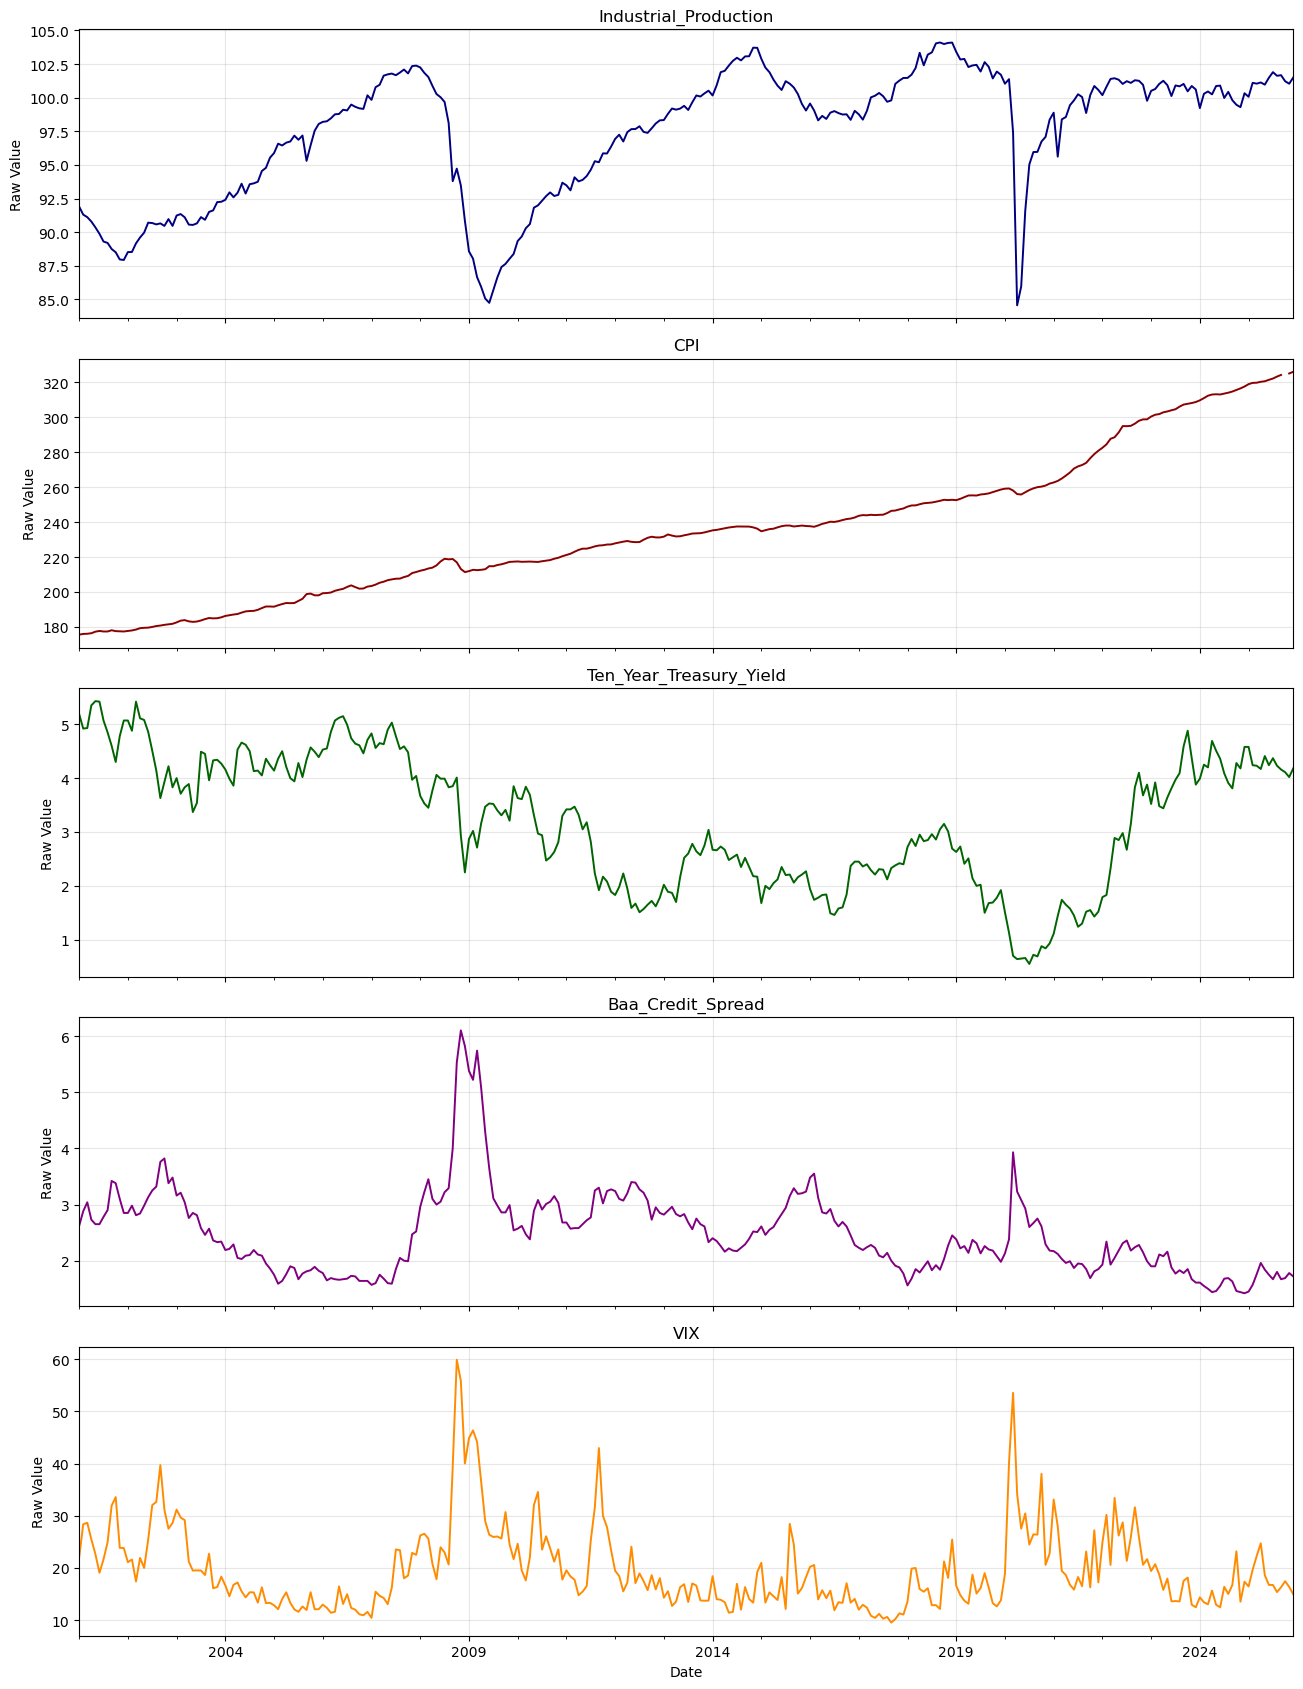

In [93]:

# Plot raw macroeconomic series

fig, axes = plt.subplots(
    nrows=5,
    ncols=1,
    figsize=(13, 17),
    sharex=True
)

plot_colors = [
    "navy",
    "darkred",
    "darkgreen",
    "purple",
    "darkorange"
]

for column, ax, color in zip(
    macro_raw_monthly.columns,
    axes,
    plot_colors
):
    macro_raw_monthly[column].plot(
        ax=ax,
        color=color,
        linewidth=1.4
    )

    ax.set_title(column)
    ax.set_ylabel("Raw Value")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Date")

plt.tight_layout()
plt.show()

In [94]:
# ---------------------------------------------------------
# Save the cleaned raw macro data
# ---------------------------------------------------------

macro_raw_monthly.to_csv(
    "macro_raw_monthly_2002_2025.csv"
)

print(
    "Saved: macro_raw_monthly_2002_2025.csv"
)

Saved: macro_raw_monthly_2002_2025.csv


In [95]:
# ---------------------------------------------------------
# Initialize the macro-factor DataFrame
# ---------------------------------------------------------

macro_factors = pd.DataFrame(
    index=macro_raw_monthly.index
)

In [96]:
# ---------------------------------------------------------
# Growth factor: Industrial Production YoY growth
# ---------------------------------------------------------

growth_raw = (
    macro_raw_monthly["Industrial_Production"]
    .pct_change(
        periods=12,
        fill_method=None
    )
    * 100
)

growth_raw.name = "Growth_Raw"

growth_raw.head(15)

DATE
2001-01-31         NaN
2001-02-28         NaN
2001-03-31         NaN
2001-04-30         NaN
2001-05-31         NaN
2001-06-30         NaN
2001-07-31         NaN
2001-08-31         NaN
2001-09-30         NaN
2001-10-31         NaN
2001-11-30         NaN
2001-12-31         NaN
2002-01-31   -3.682618
2002-02-28   -3.039974
2002-03-31   -2.137490
Freq: M, Name: Growth_Raw, dtype: float64

In [97]:
# Lag by one month to reflect publication timing.
macro_factors["Growth"] = (
    growth_raw.shift(1)
)

In [98]:
# ---------------------------------------------------------
# Inflation factor: CPI YoY inflation
# ---------------------------------------------------------

inflation_raw = (
    macro_raw_monthly["CPI"]
    .pct_change(
        periods=12,
        fill_method=None
    )
    * 100
)

inflation_raw.name = "Inflation_Raw"

inflation_raw.head(15)

DATE
2001-01-31        NaN
2001-02-28        NaN
2001-03-31        NaN
2001-04-30        NaN
2001-05-31        NaN
2001-06-30        NaN
2001-07-31        NaN
2001-08-31        NaN
2001-09-30        NaN
2001-10-31        NaN
2001-11-30        NaN
2001-12-31        NaN
2002-01-31   1.195900
2002-02-28   1.136364
2002-03-31   1.362862
Freq: M, Name: Inflation_Raw, dtype: float64

In [99]:
# Lag by one month to reflect CPI publication timing.
inflation_available = (
    inflation_raw.shift(1)
)

# If one monthly signal is unavailable, continue using
# the most recently available inflation signal.
inflation_available = (
    inflation_available.ffill(limit=1)
)

macro_factors["Inflation"] = (
    inflation_available
)

In [100]:
inflation_check = pd.DataFrame({
    "CPI": macro_raw_monthly["CPI"],
    "Inflation_Raw": inflation_raw,
    "Inflation_Available": macro_factors["Inflation"]
})

inflation_check.loc[
    "2025-08-31":"2025-12-31"
]

,CPI,Inflation_Raw,Inflation_Available
DATE,,,
2025-08-31,323.291000,2.938592,2.742618
2025-09-30,324.245000,3.022572,2.938592
2025-10-31,NaN,NaN,3.022572
2025-11-30,325.063000,2.696444,3.022572
2025-12-31,326.031000,2.653304,2.696444


In [101]:
# ---------------------------------------------------------
# Interest-rate factor: monthly change in 10-year yield
# ---------------------------------------------------------

macro_factors["Rates"] = (
    macro_raw_monthly[
        "Ten_Year_Treasury_Yield"
    ].diff()
)

In [102]:
# ---------------------------------------------------------
# Credit factor: monthly change in Baa credit spread
# ---------------------------------------------------------

macro_factors["Credit"] = (
    macro_raw_monthly[
        "Baa_Credit_Spread"
    ].diff()
)

In [103]:
# ---------------------------------------------------------
# Risk-sentiment factor: monthly change in VIX
# ---------------------------------------------------------

macro_factors["Sentiment"] = (
    macro_raw_monthly["VIX"].diff()
)

In [104]:
# ---------------------------------------------------------
# Retain the complete macro-factor sample
# ---------------------------------------------------------

macro_factors = macro_factors.loc[
    "2002-02-01":"2025-12-31"
].copy()

print("Macro-factor shape:", macro_factors.shape)
print("First date:", macro_factors.index.min())
print("Last date:", macro_factors.index.max())
print("Missing observations:")
print(macro_factors.isna().sum())

macro_factors.head()

Macro-factor shape: (287, 5)
First date: 2002-02-28 00:00:00
Last date: 2025-12-31 00:00:00
Missing observations:
Growth       0
Inflation    0
Rates        0
Credit       0
Sentiment    0
dtype: int64


,Growth,Inflation,Rates,Credit,Sentiment
DATE,,,,,
2002-02-28,-3.682618,1.195900,-0.190000,0.130000,0.500000
2002-03-31,-3.039974,1.136364,0.540000,-0.170000,-4.190000
2002-04-30,-2.137490,1.362862,-0.310000,0.030000,4.510000
2002-05-31,-1.305333,1.643991,-0.030000,0.140000,-1.930000
2002-06-30,-0.433289,1.240835,-0.220000,0.150000,5.420000


In [105]:
# ---------------------------------------------------------
# Inspect the constructed macro factors
# ---------------------------------------------------------

macro_factors.head(15)

,Growth,Inflation,Rates,Credit,Sentiment
DATE,,,,,
2002-02-28,-3.682618,1.195900,-0.190000,0.130000,0.500000
2002-03-31,-3.039974,1.136364,0.540000,-0.170000,-4.190000
2002-04-30,-2.137490,1.362862,-0.310000,0.030000,4.510000
2002-05-31,-1.305333,1.643991,-0.030000,0.140000,-1.930000
2002-06-30,-0.433289,1.240835,-0.220000,0.150000,5.420000
2002-07-31,0.920911,1.069218,-0.350000,0.120000,6.630000
2002-08-31,1.538698,1.465614,-0.370000,0.070000,0.610000
2002-09-30,1.542484,1.747463,-0.510000,0.440000,7.050000
2002-10-31,2.146064,1.516002,0.300000,0.060000,-8.550000


In [106]:
# ---------------------------------------------------------
# Check missing factor observations
# ---------------------------------------------------------

factor_coverage = pd.DataFrame({
    "First Valid Date":
        macro_factors.apply(
            lambda series: series.first_valid_index()
        ),

    "Last Valid Date":
        macro_factors.apply(
            lambda series: series.last_valid_index()
        ),

    "Valid Observations":
        macro_factors.count(),

    "Missing Observations":
        macro_factors.isna().sum()
})

factor_coverage

,First Valid Date,Last Valid Date,Valid Observations,Missing Observations
Growth,2002-02-28,2025-12-31,287,0
Inflation,2002-02-28,2025-12-31,287,0
Rates,2002-02-28,2025-12-31,287,0
Credit,2002-02-28,2025-12-31,287,0
Sentiment,2002-02-28,2025-12-31,287,0


In [107]:
# ---------------------------------------------------------
# Macro-factor descriptive statistics
# ---------------------------------------------------------

macro_factor_summary = (
    macro_factors
    .describe()
    .T
)

macro_factor_summary

,count,mean,std,min,25%,50%,75%,max
Growth,287.000000,0.597590,4.320154,-17.318282,-0.802369,1.664666,2.856950,16.552135
Inflation,287.000000,2.541577,1.789848,-1.958761,1.543727,2.263469,3.179291,8.979361
Rates,287.000000,-0.003101,0.259216,-1.080000,-0.150000,0.000000,0.150000,0.950000
Credit,287.000000,-0.003937,0.226126,-0.790000,-0.110000,-0.010000,0.080000,1.550000
Sentiment,287.000000,-0.021394,5.015418,-19.390000,-2.275000,-0.330000,2.115000,21.270000


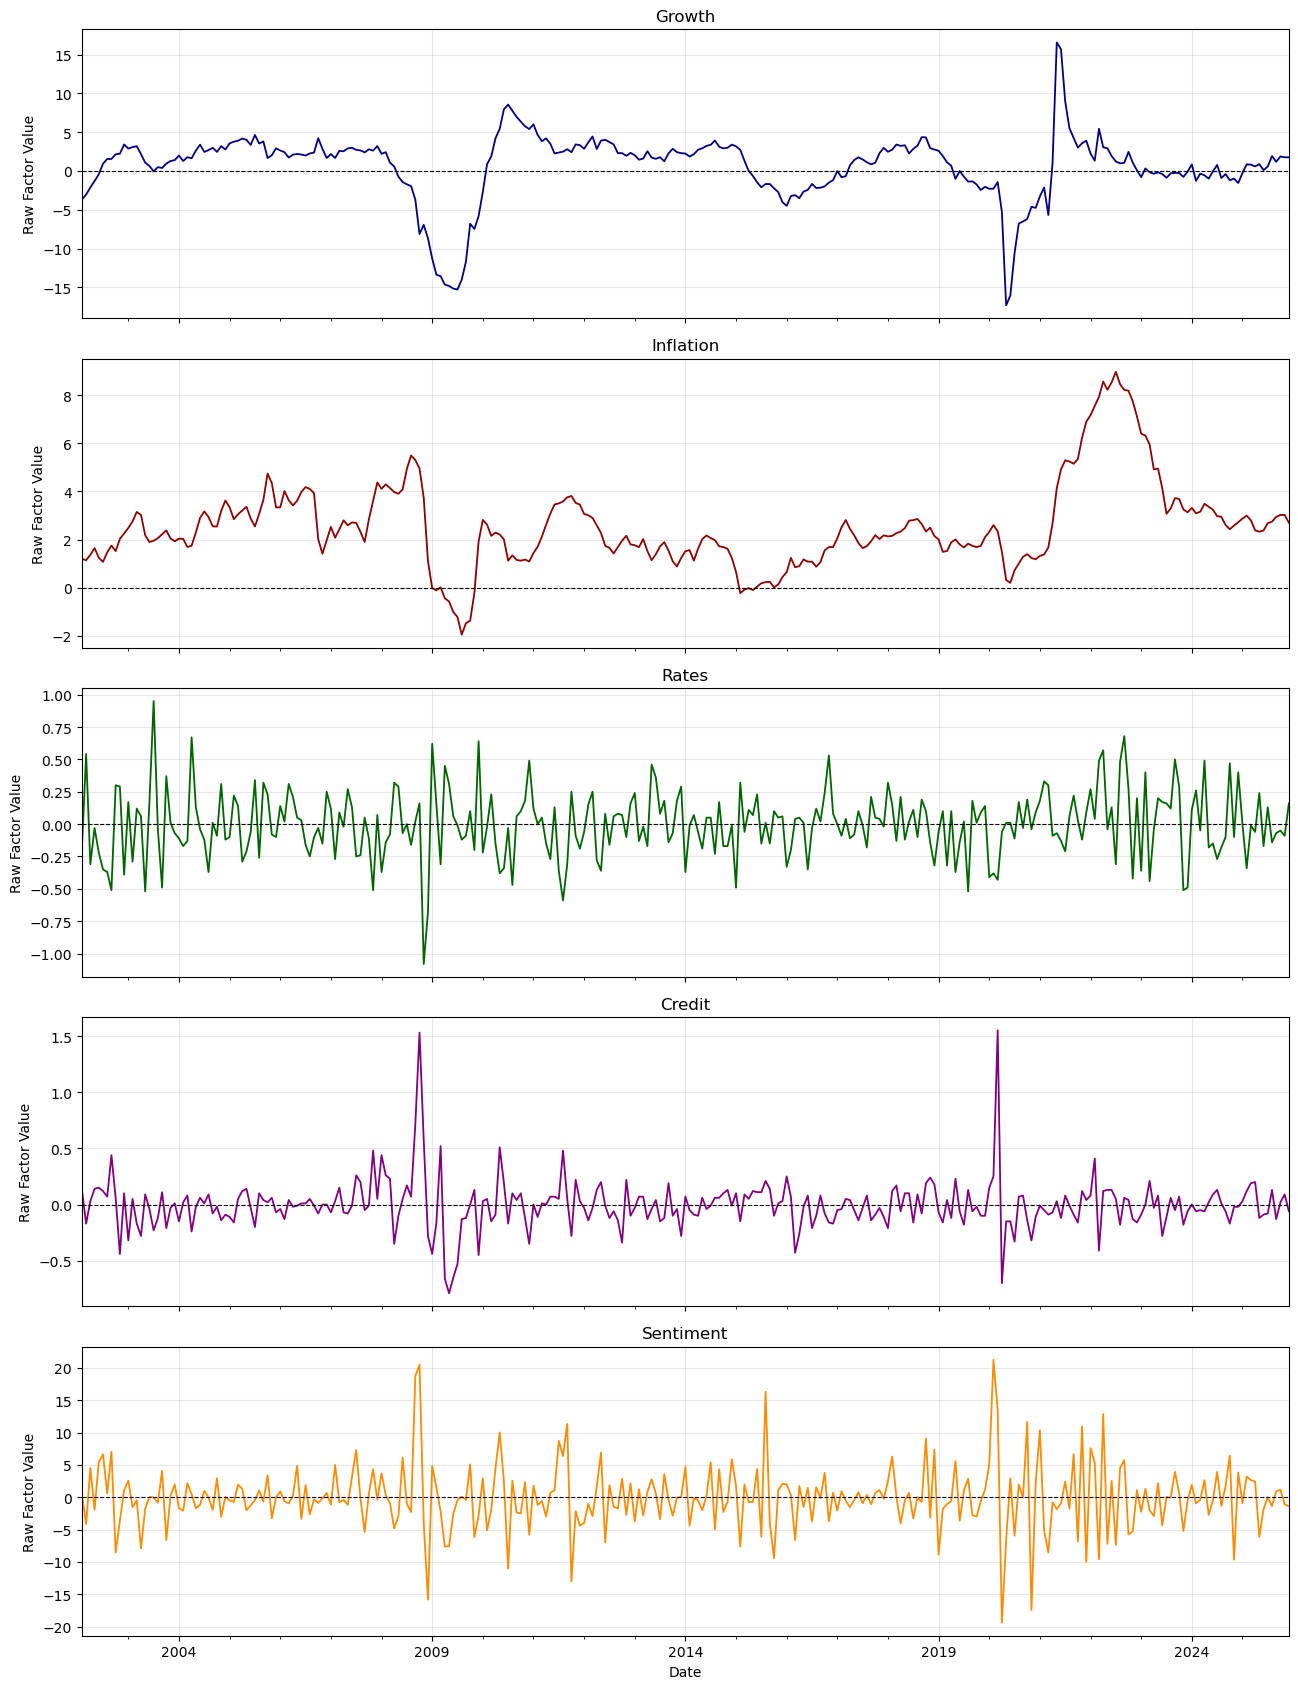

In [108]:
# ---------------------------------------------------------
# Plot the constructed macro factors
# ---------------------------------------------------------

fig, axes = plt.subplots(
    nrows=5,
    ncols=1,
    figsize=(13, 17),
    sharex=True
)

factor_colors = {
    "Growth": "navy",
    "Inflation": "darkred",
    "Rates": "darkgreen",
    "Credit": "purple",
    "Sentiment": "darkorange"
}

for factor, ax in zip(
    macro_factors.columns,
    axes
):
    macro_factors[factor].plot(
        ax=ax,
        color=factor_colors[factor],
        linewidth=1.3
    )

    ax.axhline(
        y=0,
        color="black",
        linestyle="--",
        linewidth=0.8
    )

    ax.set_title(factor)
    ax.set_ylabel("Raw Factor Value")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Date")

plt.tight_layout()
plt.show()

In [109]:
# ---------------------------------------------------------
# Save the constructed macro factors
# ---------------------------------------------------------

macro_factors.to_csv(
    "macro_factors_raw_2003_2025.csv"
)

print(
    "Saved: macro_factors_raw_2003_2025.csv"
)

Saved: macro_factors_raw_2003_2025.csv


In [110]:
macro_factors

,Growth,Inflation,Rates,Credit,Sentiment
DATE,,,,,
2002-02-28,-3.682618,1.195900,-0.190000,0.130000,0.500000
2002-03-31,-3.039974,1.136364,0.540000,-0.170000,-4.190000
2002-04-30,-2.137490,1.362862,-0.310000,0.030000,4.510000
2002-05-31,-1.305333,1.643991,-0.030000,0.140000,-1.930000
2002-06-30,-0.433289,1.240835,-0.220000,0.150000,5.420000
...,...,...,...,...,...
2025-08-31,1.918766,2.742618,-0.140000,0.130000,-1.360000
2025-09-30,1.188678,2.938592,-0.070000,-0.130000,0.920000
2025-10-31,1.863170,3.022572,-0.050000,0.020000,1.160000


In [111]:
# ---------------------------------------------------------
# Calculate rolling means and standard deviations
# ---------------------------------------------------------
STANDARDIZATION_WINDOW = 60



rolling_factor_mean = (
    macro_factors
    .rolling(
        window=STANDARDIZATION_WINDOW,
        min_periods=STANDARDIZATION_WINDOW
    )
    .mean()
)

rolling_factor_std = (
    macro_factors
    .rolling(
        window=STANDARDIZATION_WINDOW,
        min_periods=STANDARDIZATION_WINDOW
    )
    .std()
)
# ---------------------------------------------------------
# Calculate rolling macro-factor z-scores
# ---------------------------------------------------------

macro_factors_z = (
    macro_factors - rolling_factor_mean
) / rolling_factor_std

macro_factors_z.head(65)

,Growth,Inflation,Rates,Credit,Sentiment
DATE,,,,,
2002-02-28,NaN,NaN,NaN,NaN,NaN
2002-03-31,NaN,NaN,NaN,NaN,NaN
2002-04-30,NaN,NaN,NaN,NaN,NaN
2002-05-31,NaN,NaN,NaN,NaN,NaN
2002-06-30,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...
2007-02-28,-0.286476,-0.639276,-0.928653,0.386149,1.683375
2007-03-31,0.308231,-0.284020,0.372326,1.217973,-0.245896
2007-04-30,0.234448,0.125116,-0.043887,-0.368006,-0.099782


In [112]:
# ---------------------------------------------------------
# Retain the study period
# ---------------------------------------------------------

macro_factors_z = macro_factors_z.loc[
    "2007-12-01":"2025-12-31"
].copy()

print("Z-score factor shape:", macro_factors_z.shape)
print("First date:", macro_factors_z.index.min())
print("Last date:", macro_factors_z.index.max())

macro_factors_z.head()

Z-score factor shape: (217, 5)
First date: 2007-12-31 00:00:00
Last date: 2025-12-31 00:00:00


,Growth,Inflation,Rates,Credit,Sentiment
DATE,,,,,
2007-12-31,0.760418,1.951190,0.255125,0.503732,-0.102525
2008-01-31,-0.249025,1.545813,-1.380108,3.219535,1.434046
2008-02-29,-0.023427,1.704505,-0.522755,1.833807,0.148778
2008-03-31,-1.352488,1.469900,-0.281435,1.561119,-0.330762
2008-04-30,-1.767704,1.231079,1.215082,-2.442852,-1.923192


In [113]:
# ---------------------------------------------------------
# Check standardized-factor coverage
# ---------------------------------------------------------

zscore_coverage = pd.DataFrame({
    "First Valid Date":
        macro_factors_z.apply(
            lambda series: series.first_valid_index()
        ),

    "Last Valid Date":
        macro_factors_z.apply(
            lambda series: series.last_valid_index()
        ),

    "Valid Observations":
        macro_factors_z.count(),

    "Missing Observations":
        macro_factors_z.isna().sum()
})

zscore_coverage

,First Valid Date,Last Valid Date,Valid Observations,Missing Observations
Growth,2007-12-31,2025-12-31,217,0
Inflation,2007-12-31,2025-12-31,217,0
Rates,2007-12-31,2025-12-31,217,0
Credit,2007-12-31,2025-12-31,217,0
Sentiment,2007-12-31,2025-12-31,217,0


In [114]:
macro_factors_z

,Growth,Inflation,Rates,Credit,Sentiment
DATE,,,,,
2007-12-31,0.760418,1.951190,0.255125,0.503732,-0.102525
2008-01-31,-0.249025,1.545813,-1.380108,3.219535,1.434046
2008-02-29,-0.023427,1.704505,-0.522755,1.833807,0.148778
2008-03-31,-1.352488,1.469900,-0.281435,1.561119,-0.330762
2008-04-30,-1.767704,1.231079,1.215082,-2.442852,-1.923192
...,...,...,...,...,...
2025-08-31,0.286996,-0.704417,-0.717800,1.062587,-0.207891
2025-09-30,0.070421,-0.639116,-0.461818,-0.822213,0.192331
2025-10-31,0.218981,-0.621520,-0.375397,0.261047,0.276061


In [115]:
factor_comparison = pd.concat(
    {
        "Raw": macro_factors,
        "Z_Score": macro_factors_z
    },
    axis=1
)

factor_comparison.tail(12)

Raw                                           Z_Score                                        
              Growth Inflation     Rates    Credit Sentiment    Growth Inflation     Rates    Credit Sentiment
DATE                                                                                                          
2025-01-31 -0.274147  2.870691  0.000000  0.030000 -0.920000  0.004682 -0.537499 -0.181440  0.157305 -0.124974
2025-02-28  0.849003  2.990978 -0.340000  0.120000  3.200000  0.205182 -0.492455 -1.394365  0.511302  0.546750
2025-03-31  0.811986  2.801583 -0.010000  0.190000  2.650000  0.191295 -0.573094 -0.251264  1.378477  0.508701
2025-04-30  0.580245  2.381981 -0.060000  0.200000  2.420000  0.130515 -0.752824 -0.433780  1.557419  0.449815
2025-05-31  0.882352  2.325388  0.240000 -0.120000 -6.130000  0.144001 -0.802806  0.645174 -0.701509 -1.045497
2025-06-30  0.101623  2.377265 -0.170000 -0.090000 -1.840000 -0.083728 -0.811874 -0.830850 -0.499241 -0.282232
2025-07-31  0.579321  2.680454  0.130000 -0.080000 -0.010000 -0.016807 -0.709029  0.240633 -0.477332  0.021023
2025-08-31  1.918766  2.742618 -0.140000  0.130000 -1.360000  0.286996 -0.704417 -0.717800  1.062587 -0.207891
2025-09-30  1.188678  2.938592 -0.070000 -0.130000  0.920000  0.070421 -0.639116 -0.461818 -0.822213  0.192331
2025-10-31  1.863170  3.022572 -0.050000  0.020000  1.160000  0.218981 -0.621520 -0.375397  0.261047  0.276061
2025-11-30  1.759333  3.022572 -0.090000  0.090000 -1.090000  0.165411 -0.643769 -0.516323  0.757972 -0.205519
2025-12-31  1.754312  2.696444  0.160000 -0.060000 -1.400000  0.137175 -0.812951  0.381705 -0.404276 -0.256285

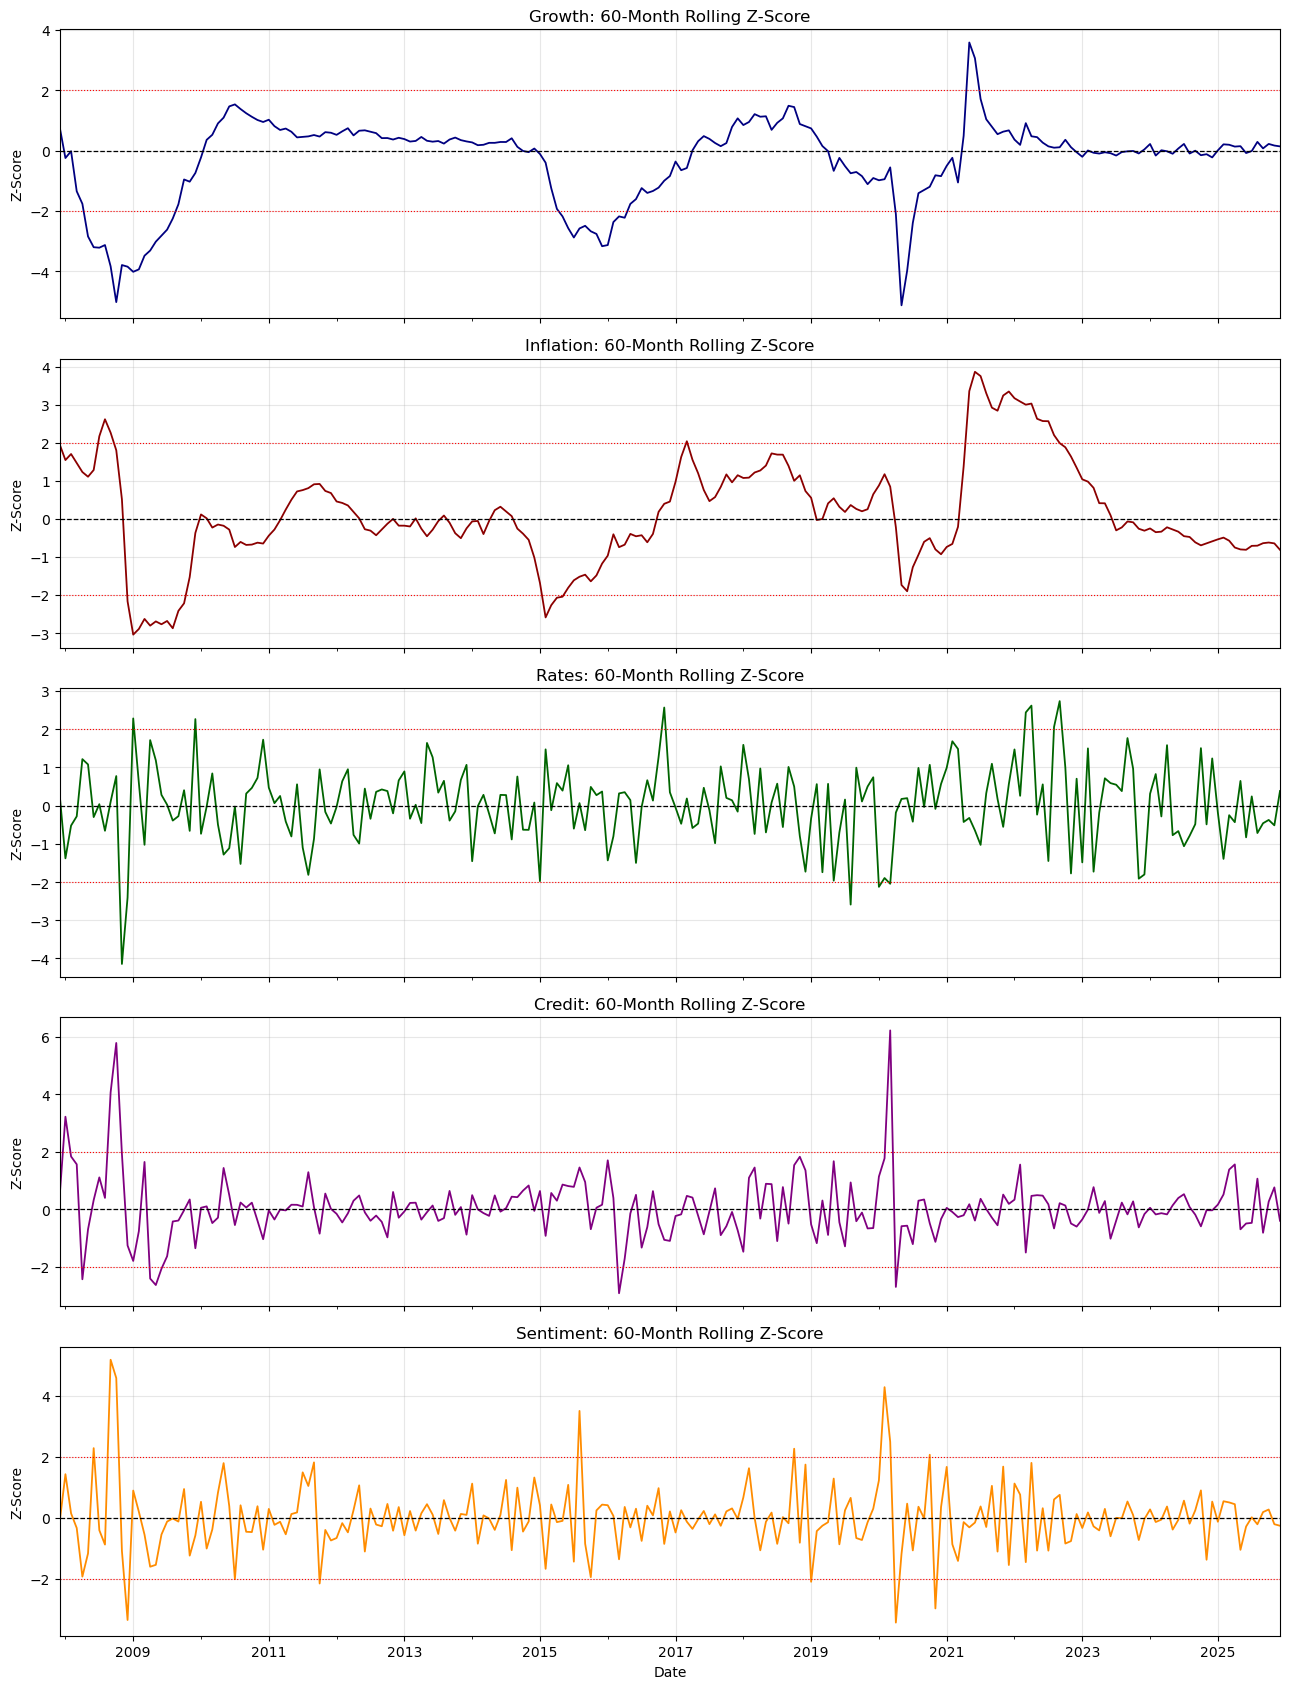

In [116]:
# ---------------------------------------------------------
# Plot standardized macro factors
# ---------------------------------------------------------

fig, axes = plt.subplots(
    nrows=5,
    ncols=1,
    figsize=(13, 17),
    sharex=True
)

factor_colors = {
    "Growth": "navy",
    "Inflation": "darkred",
    "Rates": "darkgreen",
    "Credit": "purple",
    "Sentiment": "darkorange"
}

for factor, ax in zip(
    macro_factors_z.columns,
    axes
):
    macro_factors_z[factor].plot(
        ax=ax,
        color=factor_colors[factor],
        linewidth=1.3
    )

    ax.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=0.9
    )

    ax.axhline(
        2,
        color="red",
        linestyle=":",
        linewidth=0.8
    )

    ax.axhline(
        -2,
        color="red",
        linestyle=":",
        linewidth=0.8
    )

    ax.set_title(f"{factor}: 60-Month Rolling Z-Score")
    ax.set_ylabel("Z-Score")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Date")

plt.tight_layout()
plt.show()

In [117]:
# ---------------------------------------------------------
# Save standardized macro factors
# ---------------------------------------------------------

macro_factors_z.to_csv(
    "macro_factors_zscore_2008_2025.csv"
)

print(
    "Saved: macro_factors_zscore_2008_2025.csv"
)

Saved: macro_factors_zscore_2008_2025.csv


In [119]:
# ---------------------------------------------------------
# Load monthly asset excess returns
# ---------------------------------------------------------

asset_excess_returns = pd.read_csv(
    "monthly_excess_returns_2008_2025.csv",
    index_col=0,
    parse_dates=True
)

asset_excess_returns.index.name = "DATE"

asset_excess_returns = (
    asset_excess_returns
    .sort_index()
    .loc["2008-01-01":"2025-12-31"]
)

print("Asset excess-return shape:", asset_excess_returns.shape)
print("First date:", asset_excess_returns.index.min())
print("Last date:", asset_excess_returns.index.max())

asset_excess_returns.head()

Asset excess-return shape: (216, 7)
First date: 2008-01-31 00:00:00
Last date: 2025-12-31 00:00:00


,US_Equity_Excess,International_Equity_Excess,Treasury_Excess,Investment_Grade_Credit_Excess,High_Yield_Credit_Excess,Commodities_Excess,Gold_Excess
DATE,,,,,,,
2008-01-31,-0.062928,-0.080937,0.031093,0.023192,-0.020734,0.026685,0.105950
2008-02-29,-0.028105,-0.012493,0.010130,-0.009326,-0.020957,0.109190,0.050034
2008-03-31,-0.010692,0.002440,0.011623,-0.007723,0.007711,-0.010891,-0.061741
2008-04-30,0.046619,0.053337,-0.025218,0.011403,0.032926,0.059342,-0.042632
2008-05-31,0.014048,0.010803,-0.018843,-0.023120,-0.006155,0.068006,0.008164


In [120]:
# ---------------------------------------------------------
# Inspect asset names and missing values
# ---------------------------------------------------------

print("Asset columns:")
print(asset_excess_returns.columns.tolist())

print("\nMissing observations:")
print(asset_excess_returns.isna().sum())

Asset columns:
['US_Equity_Excess', 'International_Equity_Excess', 'Treasury_Excess', 'Investment_Grade_Credit_Excess', 'High_Yield_Credit_Excess', 'Commodities_Excess', 'Gold_Excess']

Missing observations:
US_Equity_Excess                  0
International_Equity_Excess       0
Treasury_Excess                   0
Investment_Grade_Credit_Excess    0
High_Yield_Credit_Excess          0
Commodities_Excess                0
Gold_Excess                       0
dtype: int64


In [121]:
# ---------------------------------------------------------
# Align each next-month return with the preceding factor date
# ---------------------------------------------------------

next_month_excess_returns = asset_excess_returns.copy()

next_month_excess_returns.index = (
    next_month_excess_returns.index
    - pd.offsets.MonthEnd(1)
)

next_month_excess_returns.index.name = "Factor_Date"

print("Aligned return shape:", next_month_excess_returns.shape)
print("First factor date:", next_month_excess_returns.index.min())
print("Last factor date:", next_month_excess_returns.index.max())

next_month_excess_returns.head()

Aligned return shape: (216, 7)
First factor date: 2007-12-31 00:00:00
Last factor date: 2025-11-30 00:00:00


,US_Equity_Excess,International_Equity_Excess,Treasury_Excess,Investment_Grade_Credit_Excess,High_Yield_Credit_Excess,Commodities_Excess,Gold_Excess
Factor_Date,,,,,,,
2007-12-31,-0.062928,-0.080937,0.031093,0.023192,-0.020734,0.026685,0.105950
2008-01-31,-0.028105,-0.012493,0.010130,-0.009326,-0.020957,0.109190,0.050034
2008-02-29,-0.010692,0.002440,0.011623,-0.007723,0.007711,-0.010891,-0.061741
2008-03-31,0.046619,0.053337,-0.025218,0.011403,0.032926,0.059342,-0.042632
2008-04-30,0.014048,0.010803,-0.018843,-0.023120,-0.006155,0.068006,0.008164


In [122]:
# ---------------------------------------------------------
# Combine macro factors with next-month excess returns
# ---------------------------------------------------------

macro_factors_for_model = macro_factors_z.copy()
macro_factors_for_model.index.name = "Factor_Date"

model_data = macro_factors_for_model.join(
    next_month_excess_returns,
    how="inner"
)

print("Combined model-data shape:", model_data.shape)
print("First factor date:", model_data.index.min())
print("Last factor date:", model_data.index.max())
print("Total missing observations:", model_data.isna().sum().sum())

model_data.head()

Combined model-data shape: (216, 12)
First factor date: 2007-12-31 00:00:00
Last factor date: 2025-11-30 00:00:00
Total missing observations: 0


,Growth,Inflation,Rates,Credit,Sentiment,US_Equity_Excess,International_Equity_Excess,Treasury_Excess,Investment_Grade_Credit_Excess,High_Yield_Credit_Excess,Commodities_Excess,Gold_Excess
Factor_Date,,,,,,,,,,,,
2007-12-31,0.760418,1.951190,0.255125,0.503732,-0.102525,-0.062928,-0.080937,0.031093,0.023192,-0.020734,0.026685,0.105950
2008-01-31,-0.249025,1.545813,-1.380108,3.219535,1.434046,-0.028105,-0.012493,0.010130,-0.009326,-0.020957,0.109190,0.050034
2008-02-29,-0.023427,1.704505,-0.522755,1.833807,0.148778,-0.010692,0.002440,0.011623,-0.007723,0.007711,-0.010891,-0.061741
2008-03-31,-1.352488,1.469900,-0.281435,1.561119,-0.330762,0.046619,0.053337,-0.025218,0.011403,0.032926,0.059342,-0.042632
2008-04-30,-1.767704,1.231079,1.215082,-2.442852,-1.923192,0.014048,0.010803,-0.018843,-0.023120,-0.006155,0.068006,0.008164


In [123]:
# ---------------------------------------------------------
# Verify factor-to-next-month-return alignment
# ---------------------------------------------------------

alignment_check = pd.DataFrame({
    "Factor_Date": model_data.index,
    "Return_Month": (
        model_data.index
        + pd.offsets.MonthEnd(1)
    )
})

alignment_check.head(12)

,Factor_Date,Return_Month
0,2007-12-31,2008-01-31
1,2008-01-31,2008-02-29
2,2008-02-29,2008-03-31
3,2008-03-31,2008-04-30
4,2008-04-30,2008-05-31
5,2008-05-31,2008-06-30
6,2008-06-30,2008-07-31
7,2008-07-31,2008-08-31
8,2008-08-31,2008-09-30
9,2008-09-30,2008-10-31


In [125]:
# ---------------------------------------------------------
# Define predictors and prediction targets
# ---------------------------------------------------------

factor_names = [
    "Growth",
    "Inflation",
    "Rates",
    "Credit",
    "Sentiment"
]

asset_names = [
    "US_Equity_Excess",
    "International_Equity_Excess",
    "Treasury_Excess",
    "Investment_Grade_Credit_Excess",
    "High_Yield_Credit_Excess",
    "Commodities_Excess",
    "Gold_Excess"
]

X = model_data[factor_names].copy()
Y = model_data[asset_names].copy()

print("Factor matrix X:", X.shape)
print("Return matrix Y:", Y.shape)

print("\nX sample:")
display(X.head())

print("\nY sample:")
display(Y.head())

Factor matrix X: (216, 5)
Return matrix Y: (216, 7)

X sample:


,Growth,Inflation,Rates,Credit,Sentiment
Factor_Date,,,,,
2007-12-31,0.760418,1.951190,0.255125,0.503732,-0.102525
2008-01-31,-0.249025,1.545813,-1.380108,3.219535,1.434046
2008-02-29,-0.023427,1.704505,-0.522755,1.833807,0.148778
2008-03-31,-1.352488,1.469900,-0.281435,1.561119,-0.330762
2008-04-30,-1.767704,1.231079,1.215082,-2.442852,-1.923192



Y sample:


,US_Equity_Excess,International_Equity_Excess,Treasury_Excess,Investment_Grade_Credit_Excess,High_Yield_Credit_Excess,Commodities_Excess,Gold_Excess
Factor_Date,,,,,,,
2007-12-31,-0.062928,-0.080937,0.031093,0.023192,-0.020734,0.026685,0.105950
2008-01-31,-0.028105,-0.012493,0.010130,-0.009326,-0.020957,0.109190,0.050034
2008-02-29,-0.010692,0.002440,0.011623,-0.007723,0.007711,-0.010891,-0.061741
2008-03-31,0.046619,0.053337,-0.025218,0.011403,0.032926,0.059342,-0.042632
2008-04-30,0.014048,0.010803,-0.018843,-0.023120,-0.006155,0.068006,0.008164


In [126]:
# ---------------------------------------------------------
# Final alignment checks
# ---------------------------------------------------------

print("X first factor date:", X.index.min())
print("X last factor date:", X.index.max())

print("\nY first factor date:", Y.index.min())
print("Y last factor date:", Y.index.max())

print("\nNumber of observations:", len(X))
print("Number of factors:", X.shape[1])
print("Number of assets:", Y.shape[1])

print(
    "Total missing values:",
    X.isna().sum().sum()
    +
    Y.isna().sum().sum()
)

print(
    "X and Y indices identical:",
    X.index.equals(Y.index)
)

X first factor date: 2007-12-31 00:00:00
X last factor date: 2025-11-30 00:00:00

Y first factor date: 2007-12-31 00:00:00
Y last factor date: 2025-11-30 00:00:00

Number of observations: 216
Number of factors: 5
Number of assets: 7
Total missing values: 0
X and Y indices identical: True


In [127]:
# ---------------------------------------------------------
# Import regression package
# ---------------------------------------------------------

import statsmodels.api as sm

In [128]:
# ---------------------------------------------------------
# Define the first 60-month training window
# ---------------------------------------------------------

REGRESSION_WINDOW = 60

X_train_first = X.iloc[:REGRESSION_WINDOW].copy()
Y_train_first = Y.iloc[:REGRESSION_WINDOW].copy()

X_predict_first = X.iloc[[REGRESSION_WINDOW]].copy()

print("Training-factor period:")
print(X_train_first.index.min(), "to", X_train_first.index.max())

print("\nCorresponding return period:")
print(
    X_train_first.index.min() + pd.offsets.MonthEnd(1),
    "to",
    X_train_first.index.max() + pd.offsets.MonthEnd(1)
)

print("\nPrediction factor date:")
print(X_predict_first.index[0])

print("\nPredicted return month:")
print(X_predict_first.index[0] + pd.offsets.MonthEnd(1))

print("\nTraining observations:")
print(len(X_train_first))

Training-factor period:
2007-12-31 00:00:00 to 2012-11-30 00:00:00

Corresponding return period:
2008-01-31 00:00:00 to 2012-12-31 00:00:00

Prediction factor date:
2012-12-31 00:00:00

Predicted return month:
2013-01-31 00:00:00

Training observations:
60


In [129]:
# ---------------------------------------------------------
# Add an intercept to the first training window
# ---------------------------------------------------------

X_train_first_with_constant = sm.add_constant(
    X_train_first,
    has_constant="add"
)

X_predict_first_with_constant = sm.add_constant(
    X_predict_first,
    has_constant="add"
)

X_train_first_with_constant.head()

,const,Growth,Inflation,Rates,Credit,Sentiment
Factor_Date,,,,,,
2007-12-31,1.000000,0.760418,1.951190,0.255125,0.503732,-0.102525
2008-01-31,1.000000,-0.249025,1.545813,-1.380108,3.219535,1.434046
2008-02-29,1.000000,-0.023427,1.704505,-0.522755,1.833807,0.148778
2008-03-31,1.000000,-1.352488,1.469900,-0.281435,1.561119,-0.330762
2008-04-30,1.000000,-1.767704,1.231079,1.215082,-2.442852,-1.923192


In [130]:
# ---------------------------------------------------------
# Estimate the first U.S. Equity predictive regression
# ---------------------------------------------------------

first_us_equity_model = sm.OLS(
    Y_train_first["US_Equity_Excess"],
    X_train_first_with_constant
).fit()

first_us_equity_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:       US_Equity_Excess   R-squared:                       0.228
Model:                            OLS   Adj. R-squared:                  0.156
Method:                 Least Squares   F-statistic:                     3.182
Date:                Sun, 06 Sep 2026   Prob (F-statistic):             0.0137
Time:                        17:15:44   Log-Likelihood:                 97.125
No. Observations:                  60   AIC:                            -182.2
Df Residuals:                      54   BIC:                            -169.7
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0044      0.007      0.640      0.525      -0.009       0.018
Growth         0.0085      0.004      2.246      0.029       0.001       0.016
Inflation     -0.0160      0.006     -2.741      0.008      -0.028      -0.004
Rates         -0.0031      0.007     -0.432      0.667      -0.017       0.011
Credit         0.0029      0.008      0.344      0.732      -0.014       0.020
Sentiment     -0.0058      0.007     -0.868      0.389      -0.019       0.008
==============================================================================
Omnibus:                        0.825   Durbin-Watson:                   2.007
Prob(Omnibus):                  0.662   Jarque-Bera (JB):                0.659
Skew:                          -0.254   Prob(JB):                        0.719
Kurtosis:                       2.923   Cond. No.                         3.42
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [131]:
# ---------------------------------------------------------
# Inspect the estimated coefficients
# ---------------------------------------------------------

first_us_equity_coefficients = (
    first_us_equity_model.params
    .rename("Coefficient")
    .to_frame()
)

first_us_equity_coefficients

,Coefficient
const,0.004428
Growth,0.008489
Inflation,-0.016046
Rates,-0.003085
Credit,0.002859
Sentiment,-0.005845


In [132]:
# ---------------------------------------------------------
# Predict January 2013 U.S. Equity excess return
# ---------------------------------------------------------

first_us_equity_prediction = (
    first_us_equity_model.predict(
        X_predict_first_with_constant
    )
)

first_us_equity_prediction.index = (
    first_us_equity_prediction.index
    + pd.offsets.MonthEnd(1)
)

first_us_equity_prediction.name = (
    "Predicted_US_Equity_Excess_Return"
)

first_us_equity_prediction

Factor_Date
2013-01-31   0.005919
Name: Predicted_US_Equity_Excess_Return, dtype: float64

In [133]:
# ---------------------------------------------------------
# Compare predicted and realized January 2013 return
# ---------------------------------------------------------

prediction_factor_date = X_predict_first.index[0]

first_prediction_comparison = pd.Series({
    "Predicted Excess Return":
        first_us_equity_model.predict(
            X_predict_first_with_constant
        ).iloc[0],

    "Realized Excess Return":
        Y.loc[
            prediction_factor_date,
            "US_Equity_Excess"
        ],

    "Prediction Error":
        Y.loc[
            prediction_factor_date,
            "US_Equity_Excess"
        ]
        -
        first_us_equity_model.predict(
            X_predict_first_with_constant
        ).iloc[0]
})

first_prediction_comparison.name = "January 2013"

first_prediction_comparison

Predicted Excess Return   0.005919
Realized Excess Return    0.051132
Prediction Error          0.045214
Name: January 2013, dtype: float64

In [134]:
# ---------------------------------------------------------
# Estimate the first regression for all seven assets
# ---------------------------------------------------------

first_month_predictions = {}
first_month_realized_returns = {}
first_month_prediction_errors = {}

first_month_coefficients = pd.DataFrame(
    index=[
        "const",
        "Growth",
        "Inflation",
        "Rates",
        "Credit",
        "Sentiment"
    ],
    columns=asset_names,
    dtype=float
)

for asset in asset_names:

    # Estimate the asset-specific regression.
    model = sm.OLS(
        Y_train_first[asset],
        X_train_first_with_constant
    ).fit()

    # Store estimated coefficients.
    first_month_coefficients[asset] = model.params

    # Predict the next-month excess return.
    predicted_return = model.predict(
        X_predict_first_with_constant
    ).iloc[0]

    # Obtain the subsequently realized return.
    realized_return = Y.loc[
        X_predict_first.index[0],
        asset
    ]

    # Store results.
    first_month_predictions[asset] = predicted_return
    first_month_realized_returns[asset] = realized_return
    first_month_prediction_errors[asset] = (
        realized_return - predicted_return
    )

In [135]:
# ---------------------------------------------------------
# Compare predicted and realized returns for all assets
# ---------------------------------------------------------

first_month_all_asset_comparison = pd.DataFrame({
    "Predicted Excess Return":
        pd.Series(first_month_predictions),

    "Realized Excess Return":
        pd.Series(first_month_realized_returns),

    "Prediction Error":
        pd.Series(first_month_prediction_errors)
})

first_month_all_asset_comparison.index.name = "Asset"

first_month_all_asset_comparison.style.format({
    "Predicted Excess Return": "{:.2%}",
    "Realized Excess Return": "{:.2%}",
    "Prediction Error": "{:.2%}"
})

,Predicted Excess Return,Realized Excess Return,Prediction Error
Asset,,,
US_Equity_Excess,0.59%,5.11%,4.52%
International_Equity_Excess,-0.04%,3.72%,3.76%
Treasury_Excess,0.70%,-1.30%,-2.00%
Investment_Grade_Credit_Excess,0.04%,-1.30%,-1.35%
High_Yield_Credit_Excess,-0.72%,0.34%,1.06%
Commodities_Excess,1.04%,2.48%,1.44%
Gold_Excess,1.39%,-0.51%,-1.91%


In [136]:
# ---------------------------------------------------------
# Display the first-window regression coefficients
# ---------------------------------------------------------

first_month_coefficients.style.format("{:.6f}")

,US_Equity_Excess,International_Equity_Excess,Treasury_Excess,Investment_Grade_Credit_Excess,High_Yield_Credit_Excess,Commodities_Excess,Gold_Excess
const,0.004428,0.000076,0.006470,0.005410,0.004771,0.005271,0.013156
Growth,0.008489,0.009125,0.000365,0.001590,0.003861,0.011112,0.001624
Inflation,-0.016046,-0.022290,0.001525,-0.007008,-0.013830,-0.010681,-0.004328
Rates,-0.003085,-0.005213,0.000041,-0.006543,-0.015927,0.005643,-0.003783
Credit,0.002859,0.006871,0.002124,0.006255,0.006245,0.000189,-0.003912
Sentiment,-0.005845,-0.008011,0.003492,-0.002020,-0.010533,-0.014361,0.001842


In [137]:
# ---------------------------------------------------------
# Generate rolling out-of-sample predictions
# ---------------------------------------------------------

REGRESSION_WINDOW = 60

prediction_factor_dates = X.index[
    REGRESSION_WINDOW:
]

rolling_predictions = pd.DataFrame(
    index=prediction_factor_dates,
    columns=asset_names,
    dtype=float
)

rolling_realized_returns = pd.DataFrame(
    index=prediction_factor_dates,
    columns=asset_names,
    dtype=float
)

rolling_model_r_squared = pd.DataFrame(
    index=prediction_factor_dates,
    columns=asset_names,
    dtype=float
)

# Store the time-varying regression coefficients.
coefficient_names = [
    "const",
    "Growth",
    "Inflation",
    "Rates",
    "Credit",
    "Sentiment"
]

rolling_coefficients = {
    asset: pd.DataFrame(
        index=prediction_factor_dates,
        columns=coefficient_names,
        dtype=float
    )
    for asset in asset_names
}

for prediction_position in range(
    REGRESSION_WINDOW,
    len(X)
):

    # Current factor date used to predict next month's return.
    prediction_factor_date = X.index[
        prediction_position
    ]

    # Use only the preceding 60 completed observations.
    training_start = (
        prediction_position
        -
        REGRESSION_WINDOW
    )

    training_end = prediction_position

    X_train = X.iloc[
        training_start:training_end
    ]

    X_predict = X.iloc[
        [prediction_position]
    ]

    X_train_constant = sm.add_constant(
        X_train,
        has_constant="add"
    )

    X_predict_constant = sm.add_constant(
        X_predict,
        has_constant="add"
    )

    for asset in asset_names:

        Y_train = Y[asset].iloc[
            training_start:training_end
        ]

        model = sm.OLS(
            Y_train,
            X_train_constant
        ).fit()

        predicted_return = model.predict(
            X_predict_constant
        ).iloc[0]

        realized_return = Y[asset].iloc[
            prediction_position
        ]

        rolling_predictions.loc[
            prediction_factor_date,
            asset
        ] = predicted_return

        rolling_realized_returns.loc[
            prediction_factor_date,
            asset
        ] = realized_return

        rolling_model_r_squared.loc[
            prediction_factor_date,
            asset
        ] = model.rsquared

        rolling_coefficients[asset].loc[
            prediction_factor_date
        ] = model.params

In [138]:
# ---------------------------------------------------------
# Convert factor dates to realized return dates
# ---------------------------------------------------------

rolling_predictions.index = (
    rolling_predictions.index
    +
    pd.offsets.MonthEnd(1)
)

rolling_realized_returns.index = (
    rolling_realized_returns.index
    +
    pd.offsets.MonthEnd(1)
)

rolling_model_r_squared.index = (
    rolling_model_r_squared.index
    +
    pd.offsets.MonthEnd(1)
)

for asset in asset_names:

    rolling_coefficients[asset].index = (
        rolling_coefficients[asset].index
        +
        pd.offsets.MonthEnd(1)
    )

rolling_predictions.index.name = "Return_Date"
rolling_realized_returns.index.name = "Return_Date"
rolling_model_r_squared.index.name = "Return_Date"

In [139]:
# ---------------------------------------------------------
# Check rolling prediction results
# ---------------------------------------------------------

print("Rolling prediction shape:")
print(rolling_predictions.shape)

print("\nFirst predicted return month:")
print(rolling_predictions.index.min())

print("\nLast predicted return month:")
print(rolling_predictions.index.max())

print("\nMissing predicted values:")
print(rolling_predictions.isna().sum())

print("\nPrediction and realized-return indices identical:")
print(
    rolling_predictions.index.equals(
        rolling_realized_returns.index
    )
)

rolling_predictions.head()

Rolling prediction shape:
(156, 7)

First predicted return month:
2013-01-31 00:00:00

Last predicted return month:
2025-12-31 00:00:00

Missing predicted values:
US_Equity_Excess                  0
International_Equity_Excess       0
Treasury_Excess                   0
Investment_Grade_Credit_Excess    0
High_Yield_Credit_Excess          0
Commodities_Excess                0
Gold_Excess                       0
dtype: int64

Prediction and realized-return indices identical:
True


,US_Equity_Excess,International_Equity_Excess,Treasury_Excess,Investment_Grade_Credit_Excess,High_Yield_Credit_Excess,Commodities_Excess,Gold_Excess
Return_Date,,,,,,,
2013-01-31,0.005919,-0.000417,0.006991,0.000446,-0.007222,0.010423,0.013942
2013-02-28,0.013493,0.009417,0.003014,0.000775,0.000281,0.023965,0.006574
2013-03-31,0.012435,0.009737,0.007172,0.010641,0.014325,0.000118,0.011046
2013-04-30,0.012739,0.007807,0.005226,0.008491,0.012440,0.006491,0.007056
2013-05-31,0.014769,0.011094,0.005107,0.007870,0.014212,0.006764,0.014641


In [140]:
# ---------------------------------------------------------
# Compare early U.S. Equity predictions and realizations
# ---------------------------------------------------------

us_equity_rolling_comparison = pd.DataFrame({
    "Predicted":
        rolling_predictions[
            "US_Equity_Excess"
        ],

    "Realized":
        rolling_realized_returns[
            "US_Equity_Excess"
        ]
})

us_equity_rolling_comparison.head().style.format(
    "{:.2%}"
)

,Predicted,Realized
Return_Date,,
2013-01-31 00:00:00,0.59%,5.11%
2013-02-28 00:00:00,1.35%,1.27%
2013-03-31 00:00:00,1.24%,3.79%
2013-04-30 00:00:00,1.27%,1.91%
2013-05-31 00:00:00,1.48%,2.36%


In [141]:
# ---------------------------------------------------------
# Verify the first prediction month
# ---------------------------------------------------------

first_rolling_month_comparison = pd.DataFrame({
    "Predicted":
        rolling_predictions.iloc[0],

    "Realized":
        rolling_realized_returns.iloc[0]
})

first_rolling_month_comparison["Error"] = (
    first_rolling_month_comparison["Realized"]
    -
    first_rolling_month_comparison["Predicted"]
)

first_rolling_month_comparison.style.format(
    "{:.2%}"
)

,Predicted,Realized,Error
US_Equity_Excess,0.59%,5.11%,4.52%
International_Equity_Excess,-0.04%,3.72%,3.76%
Treasury_Excess,0.70%,-1.30%,-2.00%
Investment_Grade_Credit_Excess,0.04%,-1.30%,-1.35%
High_Yield_Credit_Excess,-0.72%,0.34%,1.06%
Commodities_Excess,1.04%,2.48%,1.44%
Gold_Excess,1.39%,-0.51%,-1.91%


In [142]:
# ---------------------------------------------------------
# Evaluate out-of-sample predictions by asset
# ---------------------------------------------------------

prediction_errors = (
    rolling_realized_returns
    -
    rolling_predictions
)

rmse_by_asset = np.sqrt(
    prediction_errors
    .pow(2)
    .mean()
)

mae_by_asset = (
    prediction_errors
    .abs()
    .mean()
)

prediction_correlation = (
    rolling_predictions
    .corrwith(
        rolling_realized_returns
    )
)

directional_accuracy = (
    np.sign(rolling_predictions)
    ==
    np.sign(rolling_realized_returns)
).mean()

prediction_evaluation = pd.DataFrame({
    "RMSE": rmse_by_asset,
    "MAE": mae_by_asset,
    "Prediction Correlation":
        prediction_correlation,
    "Directional Accuracy":
        directional_accuracy
})

prediction_evaluation.index.name = "Asset"

prediction_evaluation.style.format({
    "RMSE": "{:.2%}",
    "MAE": "{:.2%}",
    "Prediction Correlation": "{:.3f}",
    "Directional Accuracy": "{:.2%}"
})

,RMSE,MAE,Prediction Correlation,Directional Accuracy
Asset,,,,
US_Equity_Excess,4.44%,3.32%,-0.092,61.54%
International_Equity_Excess,4.42%,3.27%,0.011,57.05%
Treasury_Excess,1.92%,1.50%,0.017,44.87%
Investment_Grade_Credit_Excess,2.36%,1.74%,-0.050,50.64%
High_Yield_Credit_Excess,2.29%,1.59%,-0.015,54.49%
Commodities_Excess,5.07%,4.00%,0.099,51.28%
Gold_Excess,4.58%,3.73%,0.034,50.64%


In [143]:
# ---------------------------------------------------------
# Calculate monthly cross-sectional Rank IC
# ---------------------------------------------------------

monthly_rank_ic = pd.Series(
    index=rolling_predictions.index,
    dtype=float,
    name="Rank_IC"
)

for return_date in rolling_predictions.index:

    predicted_cross_section = (
        rolling_predictions.loc[return_date]
    )

    realized_cross_section = (
        rolling_realized_returns.loc[return_date]
    )

    monthly_rank_ic.loc[return_date] = (
        predicted_cross_section.corr(
            realized_cross_section,
            method="spearman"
        )
    )

monthly_rank_ic.head()

Return_Date
2013-01-31   -0.142857
2013-02-28   -0.178571
2013-03-31    0.428571
2013-04-30    0.500000
2013-05-31    0.178571
Name: Rank_IC, dtype: float64

In [144]:
# ---------------------------------------------------------
# Summarize cross-sectional Rank IC performance
# ---------------------------------------------------------

rank_ic_mean = monthly_rank_ic.mean()
rank_ic_std = monthly_rank_ic.std()

rank_ic_ir = (
    rank_ic_mean
    /
    rank_ic_std
    *
    np.sqrt(12)
)

positive_rank_ic_ratio = (
    monthly_rank_ic > 0
).mean()

rank_ic_t_statistic = (
    rank_ic_mean
    /
    (
        rank_ic_std
        /
        np.sqrt(monthly_rank_ic.count())
    )
)

rank_ic_summary = pd.Series({
    "Mean Monthly Rank IC":
        rank_ic_mean,

    "Monthly Rank IC Standard Deviation":
        rank_ic_std,

    "Annualized Rank ICIR":
        rank_ic_ir,

    "Positive Rank IC Ratio":
        positive_rank_ic_ratio,

    "Rank IC t-statistic":
        rank_ic_t_statistic
})

rank_ic_summary

Mean Monthly Rank IC                 0.105311
Monthly Rank IC Standard Deviation   0.494386
Annualized Rank ICIR                 0.737904
Positive Rank IC Ratio               0.551282
Rank IC t-statistic                  2.660551
dtype: float64

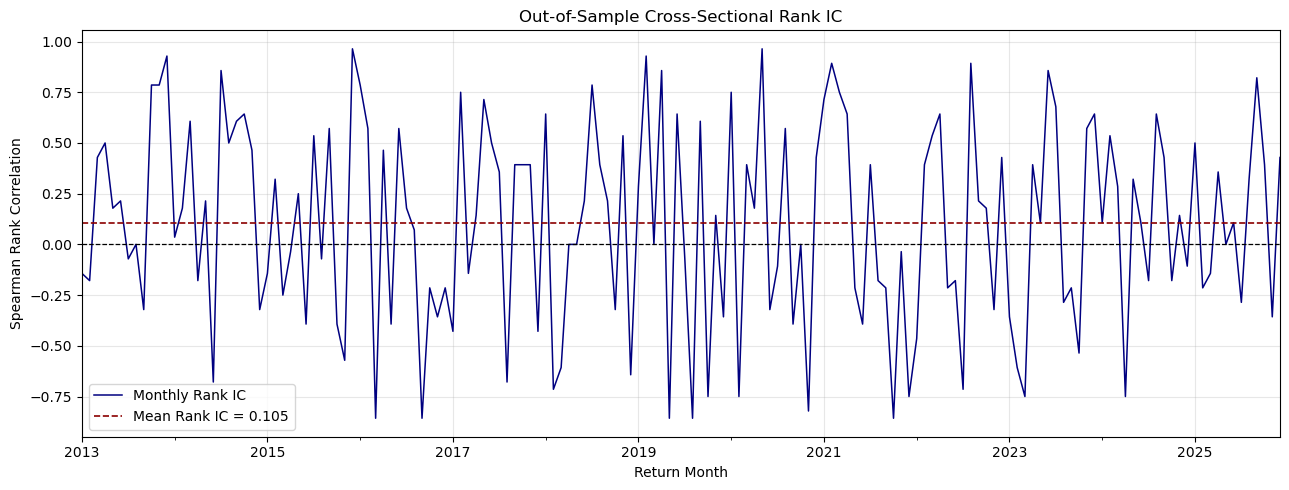

In [146]:
# ---------------------------------------------------------
# Plot monthly Rank IC
# ---------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(13, 5)
)

monthly_rank_ic.plot(
    ax=ax,
    color="navy",
    linewidth=1.1,
    label="Monthly Rank IC"
)

ax.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=0.9
)

ax.axhline(
    y=rank_ic_mean,
    color="darkred",
    linestyle="--",
    linewidth=1.2,
    label=f"Mean Rank IC = {rank_ic_mean:.3f}"
)

ax.set_title(
    "Out-of-Sample Cross-Sectional Rank IC"
)
ax.set_xlabel("Return Month")
ax.set_ylabel("Spearman Rank Correlation")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

In [147]:
# ---------------------------------------------------------
# Newey-West test for the mean monthly Rank IC
# ---------------------------------------------------------

rank_ic_regression_data = monthly_rank_ic.dropna()

rank_ic_constant = np.ones(
    len(rank_ic_regression_data)
)

rank_ic_mean_model = sm.OLS(
    rank_ic_regression_data.values,
    rank_ic_constant
).fit(
    cov_type="HAC",
    cov_kwds={
        "maxlags": 6
    }
)

newey_west_mean_rank_ic = (
    rank_ic_mean_model.params[0]
)

newey_west_t_statistic = (
    rank_ic_mean_model.tvalues[0]
)

newey_west_p_value = (
    rank_ic_mean_model.pvalues[0]
)

newey_west_rank_ic_results = pd.Series({
    "Mean Monthly Rank IC":
        newey_west_mean_rank_ic,

    "Newey-West t-statistic":
        newey_west_t_statistic,

    "Newey-West p-value":
        newey_west_p_value
})

newey_west_rank_ic_results

Mean Monthly Rank IC     0.105311
Newey-West t-statistic   3.191440
Newey-West p-value       0.001416
dtype: float64

In [148]:
# ---------------------------------------------------------
# Save rolling out-of-sample results
# ---------------------------------------------------------

rolling_predictions.to_csv(
    "rolling_predicted_excess_returns_2013_2025.csv"
)

rolling_realized_returns.to_csv(
    "rolling_realized_excess_returns_2013_2025.csv"
)

monthly_rank_ic.to_csv(
    "monthly_rank_ic_2013_2025.csv"
)

print("Saved rolling prediction results.")

Saved rolling prediction results.
